<a href="https://colab.research.google.com/github/ursuperwomen/Data-Protection-App/blob/main/RBLJAN_SOTA_Reproduction_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# RBLJAN & SOTA-RBLJAN++: Deep Analysis, Reproduction, and SOTA Enhancement Suite

**Reference Paper:** *RBLJAN: Robust Byte-Label Joint Attention Network for Network Traffic Classification* (Xi Xiao et al., IEEE Transactions on Dependable and Secure Computing, Vol. 22, No. 3, May/June 2025).

---

## 1. Deep Architectural Analysis of RBLJAN

### 1.1 Data Preprocessing (`Section III-B`)
* **Masking**:
  1. **Ethernet II Header**: Stripped completely (MAC addresses and EtherType carry local link-layer bias).
  2. **IPv4 Header**: Masks Source/Destination IP addresses (bytes 12–19), Identification (bytes 4–5), and Header Checksum (bytes 10–11) with zeros; preserves **IP Header Length (IHL)**, **Total Length**, **Time-to-Live (TTL)**, and **Protocol**.
  3. **TCP/UDP Header**: Zeroes out ephemeral/random ports while preserving **Well-Known Ports** (e.g., 80, 443, 53, 22), TCP Header Length, TCP Flags, and Window Size.
  4. **Payload Filtering**: Legitimate traffic tasks discard zero-payload packets; malware identification (`USTC-TFC`) retains zero-payload packets (crucial for Port Scan and DDoS/SYN-flood behaviors).
* **Vectorization**:
  * Converts raw packet bytes into integers in $[0, 255]$ and splits each packet into:
    $$(H, P) = (\{b_i\}_{i=1}^{M}, \{b_i\}_{i=M+1}^{N})$$
    where Header length $M = 50$ bytes and Payload length $N - M = 1450$ bytes ($N = 1500$). Shorter sequences are padded with token `256`.

### 1.2 Packet-Level Classifier (`Section III-C`)
1. **Embedding Module**:
   * Maps Header bytes $H$ and Payload bytes $P$ into $\mathbb{R}^{E}$ ($E=256$) using separate embedding tables, adding Sinusoidal Positional Encoding $Q_i$: $B_i = B'_i + Q_i$.
   * Embeds $T$ candidate labels into $L^{(h)}, L^{(p)} \in \mathbb{R}^{T \times E}$.
2. **Joint Attention Module**:
   * **Similarity Calculation (SC) Unit**: Computes cosine similarity matrix $G \in \mathbb{R}^{S \times T}$:
     $$G_{(i,j)} = \frac{B_i^\top L_j}{\|B_i\|_2 \|L_j\|_2}$$
   * **Byte Attention Encoder**: Groups $n$ consecutive bytes ($n^{(h)}=17, n^{(p)}=65$) into $S - n + 1$ byte units by averaging their embeddings. Applies $K=8$ 1D-CNN kernels over $n \times T$ regions of $G$, followed by BatchNorm, ReLU, MaxPooling across the $K$ kernels, and Softmax normalization to produce weights $\alpha$, yielding $h_b^{(h)}, h_b^{(p)} \in \mathbb{R}^{E}$.
   * **Label Attention Encoder**: Splits the $S$ byte dimension of $G$ into $s$ segments ($S' = S/s$), applies a two-stage fully connected network + Softmax to obtain label attention weights $\beta \in \mathbb{R}^{T}$, yielding $h_l^{(h)}, h_l^{(p)} \in \mathbb{R}^{E}$.
3. **Classification & Regularization Objective**:
   * Concatenates the four representations: $h = [h_b^{(h)} \| h_b^{(p)} \| h_l^{(h)} \| h_l^{(p)}] \in \mathbb{R}^{4E}$.
   * Optimizes Focal Loss ($\gamma=2$) on packet predictions plus Cross-Entropy Label Regularization ($\lambda=0.1$) on $\hat{L}_t = [L_t^{(h)} \| L_t^{(p)} \| L_t^{(h)} \| L_t^{(p)}]$:
     $$\mathcal{L}_{tot} = \mathcal{L}_{pac} + \lambda \mathcal{L}_{reg}$$

---

## 2. Diagnosis of Original Limitations & Our 4 SOTA Innovations (`SOTA-RBLJAN++`)

| Bottleneck in Original RBLJAN | Root Cause in Paper | Our SOTA Innovation in `SOTA-RBLJAN++` |
| :--- | :--- | :--- |
| **1. Non-Differentiable Generator Discretization** | Fig. 3 multiplies generator sigmoid output by `256` and truncates to integer IDs before feeding into `nn.Embedding`, breaking gradient flow $\nabla_{\theta_g}\mathcal{L}_{adv}$. | **Differentiable Straight-Through Gumbel-Softmax Adversarial Generator (`STE-AdvGAN`)**: Uses hard Gumbel-Softmax over the 256 byte tokens multiplied directly by the classifier's embedding matrix so exact gradients flow end-to-end into $G$. |
| **2. Positional Fragility Under Byte Injection** | Injecting $k$ adversarial bytes between $H$ and $P$ shifts every payload byte index by $+k$, misaligning static sinusoidal positional encodings $Q_i$. | **Shift-Equivariant Depthwise Relative Positional Encoding (`ConvRPE`) + Multi-Scale Pyramid Byte Attention (`MS-ByteAE`)**: Replaces absolute payload PE with depthwise relative positional convolutions and multi-scale windows ($n \in \{9, 25, 65\}$). |
| **3. Flat Cosine Similarity & Class Overlap** | Unscaled cosine similarity in $[-1, 1]$ produces high-entropy softmax distributions across $S=1450$ payload bytes. | **Learnable Temperature-Scaled Similarity ($\tau$-SC) & Hyperspherical Orthogonality Regularization ($\mathcal{L}_{ortho}$)**: Scales similarity by learnable $1/\tau$ and enforces $\|L L^\top - I\|_F^2$ orthogonality across class prototypes. |
| **4. Zero-Payload Malware Vulnerability (`Miuref`)** | Static concatenation $h = [h_b^{(h)} \| h_b^{(p)} \| h_l^{(h)} \| h_l^{(p)}]$ gives equal weight to payload branches even when a packet has 0 payload bytes (`Miuref` gets only 88.95% packet F1 in Table VI). | **Uncertainty-Aware Cross-Modal Gated Fusion (`CGF`)**: Dynamically gates the 4 branches based on valid payload density and branch confidence, routing zero-payload packets cleanly through Header representations. |


In [25]:
import os
import time
import math
import random
import warnings
from typing import Tuple, Dict, List, Optional

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import precision_recall_fscore_support, accuracy_score
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[INFO] Running on device: {DEVICE}")


[INFO] Running on device: cuda


## 3. Data Preprocessing (`Section III-B`) & Realistic Traffic Synthesizer
Includes the exact `preprocess_raw_packet_bytes` function for raw PCAP/Scapy packets and `RealisticTrafficDataset` reproducing the 10 malware classes of `USTC-TFC` (including zero-payload scanning packets in `Miuref` and `Neris`).


In [26]:
WELL_KNOWN_PORTS = {20, 21, 22, 23, 25, 53, 67, 68, 80, 110, 123, 143, 161, 443, 445, 993, 995, 3306, 3389, 8080}
PAD_TOKEN = 256
NUM_BYTE_TOKENS = 257  # 0..255 + 256 (padding token)

USTC_TFC_CLASSES = [
    "Cridex", "Geodo", "Htbot", "Miuref", "Neris",
    "Nsis-ay", "Shifu", "Tinba", "Virut", "Zeus"
]

def preprocess_raw_packet_bytes(ip_packet_bytes: bytes, M: int = 50, P_len: int = 1450) -> Tuple[np.ndarray, np.ndarray]:
    """
    Exact implementation of Section III-B Masking & Vectorization for a raw IP packet (Ethernet stripped).
    """
    raw = bytearray(ip_packet_bytes)
    if len(raw) < 20:
        raw.extend([0] * (20 - len(raw)))

    # 1. IP Header Length (IHL) in 32-bit words
    ihl = (raw[0] & 0x0F) * 4
    ihl = max(20, min(ihl, len(raw)))

    # Mask Identification (bytes 4-5), Header Checksum (bytes 10-11), Src/Dst IP (bytes 12-19)
    raw[4:6] = b'\x00\x00'
    raw[10:12] = b'\x00\x00'
    raw[12:20] = b'\x00' * 8

    proto = raw[9]
    l4_hlen = 0
    # 2. TCP (6) or UDP (17) Header port masking
    if proto in (6, 17) and len(raw) >= ihl + 4:
        src_port = (raw[ihl] << 8) | raw[ihl + 1]
        dst_port = (raw[ihl + 2] << 8) | raw[ihl + 3]
        if src_port not in WELL_KNOWN_PORTS:
            raw[ihl:ihl + 2] = b'\x00\x00'
        if dst_port not in WELL_KNOWN_PORTS:
            raw[ihl + 2:ihl + 4] = b'\x00\x00'

        if proto == 6 and len(raw) >= ihl + 20:
            l4_hlen = ((raw[ihl + 12] >> 4) & 0x0F) * 4
            l4_hlen = max(20, l4_hlen)
            raw[ihl + 4:ihl + 12] = b'\x00' * 8
            raw[ihl + 16:ihl + 18] = b'\x00\x00'
        elif proto == 17 and len(raw) >= ihl + 8:
            l4_hlen = 8
            raw[ihl + 6:ihl + 8] = b'\x00\x00'

    header_end = min(len(raw), ihl + l4_hlen)
    header_bytes = list(raw[:header_end])
    payload_bytes = list(raw[header_end:])

    H = np.full(M, PAD_TOKEN, dtype=np.int64)
    P = np.full(P_len, PAD_TOKEN, dtype=np.int64)

    h_copy = min(len(header_bytes), M)
    p_copy = min(len(payload_bytes), P_len)
    H[:h_copy] = header_bytes[:h_copy]
    P[:p_copy] = payload_bytes[:p_copy]

    return H, P


class RealisticTrafficDataset(Dataset):
    """
    Synthesizes realistic encrypted & malware traffic matching USTC-TFC statistical properties:
    - Header fields placed at exact RFC 791 / RFC 793 offsets.
    - Class-specific encrypted payload byte motifs & Markov transitions.
    - 'Miuref' (class 3) and 'Neris' (class 4) include high proportions of zero-payload scanning/SYN packets.
    """
    def __init__(
        self,
        num_samples: int = 2000,
        num_classes: int = 10,
        M: int = 50,
        P_len: int = 1450,
        is_flow: bool = False,
        U: int = 15,
        seed: int = 42
    ):
        super().__init__()
        self.num_samples = num_samples
        self.num_classes = num_classes
        self.M = M
        self.P_len = P_len
        self.is_flow = is_flow
        self.U = U

        rng = np.random.RandomState(seed)
        self.labels = rng.randint(0, num_classes, size=num_samples)

        self.class_ttls = [64, 128, 64, 255, 128, 64, 128, 64, 128, 255]
        self.class_protos = [6, 6, 6, 6, 17, 17, 6, 6, 17, 6]
        self.class_ports = [443, 80, 443, 80, 53, 53, 443, 8080, 53, 443]
        self.class_win_low = [29200 & 0xFF, 8192 & 0xFF, 65535 & 0xFF, 1024 & 0xFF, 0, 0, 14600 & 0xFF, 4096 & 0xFF, 0, 32768 & 0xFF]
        self.class_flags = [0x18, 0x18, 0x10, 0x02, 0x00, 0x00, 0x18, 0x18, 0x00, 0x18]

        self.class_signatures = [
            rng.randint(0, 256, size=(3, 24)) for _ in range(num_classes)
        ]

        if not is_flow:
            self.H = np.full((num_samples, M), PAD_TOKEN, dtype=np.int64)
            self.P = np.full((num_samples, P_len), PAD_TOKEN, dtype=np.int64)
            for idx in range(num_samples):
                c = self.labels[idx]
                h, p = self._generate_single_packet(c, rng)
                self.H[idx] = h
                self.P[idx] = p
        else:
            self.H = np.full((num_samples, U, M), PAD_TOKEN, dtype=np.int64)
            self.P = np.full((num_samples, U, P_len), PAD_TOKEN, dtype=np.int64)
            for idx in range(num_samples):
                c = self.labels[idx]
                for u in range(U):
                    h, p = self._generate_single_packet(c, rng, pkt_idx_in_flow=u)
                    self.H[idx, u] = h
                    self.P[idx, u] = p

    def _generate_single_packet(self, c: int, rng: np.random.RandomState, pkt_idx_in_flow: int = 0) -> Tuple[np.ndarray, np.ndarray]:
        h = np.full(self.M, PAD_TOKEN, dtype=np.int64)
        p = np.full(self.P_len, PAD_TOKEN, dtype=np.int64)

        zero_payload = (c == 3 and rng.rand() < 0.60) or (c == 4 and rng.rand() < 0.30) or (pkt_idx_in_flow in (0, 1) and rng.rand() < 0.5)
        payload_len = 0 if zero_payload else rng.randint(120, 900)
        header_len = 40 if self.class_protos[c] == 6 else 28
        total_len = header_len + payload_len

        h[:header_len] = 0
        h[0] = 0x45 + (rng.randint(0, 2) if rng.rand() < 0.1 else 0)
        h[2] = (total_len >> 8) & 0xFF
        h[3] = total_len & 0xFF
        h[8] = max(1, min(255, self.class_ttls[c] - rng.randint(0, 5)))
        h[9] = self.class_protos[c]

        port = self.class_ports[c] if rng.rand() < 0.85 else rng.choice(list(WELL_KNOWN_PORTS))
        if pkt_idx_in_flow % 2 == 0:
            h[22] = (port >> 8) & 0xFF
            h[23] = port & 0xFF
        else:
            h[20] = (port >> 8) & 0xFF
            h[21] = port & 0xFF

        if self.class_protos[c] == 6:
            h[32] = 0x50
            h[33] = self.class_flags[c] if not zero_payload else 0x02
            h[34] = ((64 + c * 12) + rng.randint(-4, 5)) & 0xFF
            h[35] = (self.class_win_low[c] + rng.randint(-3, 4)) & 0xFF

        if rng.rand() < 0.18:
            random_c = rng.randint(0, self.num_classes)
            h[8] = self.class_ttls[random_c]
            h[22:24] = [(self.class_ports[random_c] >> 8) & 0xFF, self.class_ports[random_c] & 0xFF]

        if payload_len > 0:
            p[:payload_len] = rng.randint(0, 256, size=payload_len)
            for sig in self.class_signatures[c]:
                if payload_len > len(sig) + 30:
                    pos = rng.randint(5, min(payload_len - len(sig) - 1, 400))
                    noisy_sig = sig.copy()
                    flip_mask = rng.rand(len(sig)) < 0.15
                    noisy_sig[flip_mask] = rng.randint(0, 256, size=flip_mask.sum())
                    p[pos:pos + len(sig)] = noisy_sig

        return h, p

    def __len__(self) -> int:
        return self.num_samples

    def __getitem__(self, idx: int):
        return (
            torch.tensor(self.H[idx], dtype=torch.long),
            torch.tensor(self.P[idx], dtype=torch.long),
            torch.tensor(self.labels[idx], dtype=torch.long)
        )


def inject_adversarial_noise_bytes(
    H: torch.Tensor,
    P: torch.Tensor,
    num_injected_bytes: int
) -> Tuple[torch.Tensor, torch.Tensor]:
    """
    Inserts `num_injected_bytes` of random bytes in [0, 255] between Header H and Payload P,
    then truncates the resulting payload back to length P_len (1450).
    """
    if num_injected_bytes <= 0:
        return H, P
    B, P_len = P.shape
    noise = torch.randint(0, 256, (B, num_injected_bytes), device=P.device, dtype=P.dtype)
    P_Corrupted = torch.cat([noise, P], dim=1)[:, :P_len]
    return H, P_Corrupted


## 4. Exact Baseline `RBLJAN` Implementation (`Section III-C` & `III-D`)
Implements the Embedding Module, Similarity Calculation Unit, 1D-CNN Byte Attention Encoder, Two-Stage Grouped Label Attention Encoder, Deconvolution Adversarial Traffic Generator, and Focal + Label Regularization Losses.


In [27]:
class SinusoidalPositionalEncoding(nn.Module):
    def __init__(self, max_len: int, d_model: int):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return x + self.pe[:, :x.size(1), :]


class ByteAttentionEncoder(nn.Module):
    def __init__(self, n_window: int, num_classes: int, K_kernels: int = 8, pad_same: bool = False):
        super().__init__()
        self.n_window = n_window
        self.pad_same = pad_same
        padding = n_window // 2 if pad_same else 0
        self.conv = nn.Conv1d(
            in_channels=num_classes,
            out_channels=K_kernels,
            kernel_size=n_window,
            stride=1,
            padding=padding
        )
        self.bn = nn.BatchNorm1d(K_kernels)
        self.avg_pool = nn.AvgPool1d(kernel_size=n_window, stride=1, padding=padding)

    def forward(self, B_emb: torch.Tensor, G: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        G_t = G.transpose(1, 2)
        cand_scores = F.relu(self.bn(self.conv(G_t)))
        max_scores, _ = torch.max(cand_scores, dim=1)
        alpha = F.softmax(max_scores, dim=-1)

        byte_units = self.avg_pool(B_emb.transpose(1, 2)).transpose(1, 2)
        min_len = min(alpha.size(1), byte_units.size(1))
        alpha = alpha[:, :min_len]
        byte_units = byte_units[:, :min_len, :]

        h_b = torch.bmm(alpha.unsqueeze(1), byte_units).squeeze(1)
        return h_b, alpha


class LabelAttentionEncoder(nn.Module):
    def __init__(self, S_len: int, s_groups: int = 10):
        super().__init__()
        self.S_len = S_len
        self.s_groups = s_groups
        assert S_len % s_groups == 0, f"S_len ({S_len}) must be divisible by s_groups ({s_groups})"
        self.group_size = S_len // s_groups

        self.fc1 = nn.Linear(self.group_size, 1)
        self.fc2 = nn.Linear(s_groups, 1)

    def forward(self, L_emb: torch.Tensor, G: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        B, S, T = G.shape
        G_grouped = G.transpose(1, 2).contiguous().view(B, T, self.s_groups, self.group_size)
        stage1 = F.relu(self.fc1(G_grouped).squeeze(-1))
        logits = self.fc2(stage1).squeeze(-1)
        beta = F.softmax(logits, dim=-1)
        h_l = torch.matmul(beta, L_emb)
        return h_l, beta


class RBLJANClassifier(nn.Module):
    def __init__(
        self,
        num_classes: int = 10,
        M: int = 50,
        P_len: int = 1450,
        E: int = 256,
        n_h: int = 17,
        n_p: int = 65,
        K: int = 8,
        dropout: float = 0.5,
        use_label_attention: bool = True,
        separate_header_payload: bool = True,
        pad_header_for_viz: bool = False
    ):
        super().__init__()
        self.num_classes = num_classes
        self.M = M
        self.P_len = P_len
        self.E = E
        self.use_label_attention = use_label_attention
        self.separate_header_payload = separate_header_payload

        if separate_header_payload:
            self.header_byte_emb = nn.Embedding(NUM_BYTE_TOKENS, E, padding_idx=PAD_TOKEN)
            self.payload_byte_emb = nn.Embedding(NUM_BYTE_TOKENS, E, padding_idx=PAD_TOKEN)
            self.header_pos_enc = SinusoidalPositionalEncoding(M, E)
            self.payload_pos_enc = SinusoidalPositionalEncoding(P_len, E)

            self.header_label_emb = nn.Embedding(num_classes, E)
            self.payload_label_emb = nn.Embedding(num_classes, E)

            self.header_byte_ae = ByteAttentionEncoder(n_h, num_classes, K, pad_same=pad_header_for_viz)
            self.payload_byte_ae = ByteAttentionEncoder(n_p, num_classes, K, pad_same=False)

            if use_label_attention:
                self.header_label_ae = LabelAttentionEncoder(M, s_groups=5)
                self.payload_label_ae = LabelAttentionEncoder(P_len, s_groups=10)
                clf_in_dim = 4 * E
            else:
                clf_in_dim = 2 * E
        else:
            total_len = M + P_len
            self.pkt_byte_emb = nn.Embedding(NUM_BYTE_TOKENS, E, padding_idx=PAD_TOKEN)
            self.pkt_pos_enc = SinusoidalPositionalEncoding(total_len, E)
            self.pkt_label_emb = nn.Embedding(num_classes, E)
            self.pkt_byte_ae = ByteAttentionEncoder(50, num_classes, K)
            self.pkt_label_ae = LabelAttentionEncoder(total_len, s_groups=10)
            clf_in_dim = 2 * E

        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(clf_in_dim, num_classes)

    @staticmethod
    def compute_cosine_similarity(B_emb: torch.Tensor, L_emb: torch.Tensor) -> torch.Tensor:
        B_norm = F.normalize(B_emb, p=2, dim=-1)
        L_norm = F.normalize(L_emb, p=2, dim=-1)
        return torch.matmul(B_norm, L_norm.t())

    def forward(
        self,
        H: torch.Tensor,
        P: torch.Tensor,
        return_details: bool = False
    ):
        label_ids = torch.arange(self.num_classes, device=H.device)

        if not self.separate_header_payload:
            X = torch.cat([H, P], dim=1)
            B_emb = self.pkt_pos_enc(self.pkt_byte_emb(X))
            L_emb = self.pkt_label_emb(label_ids)
            G = self.compute_cosine_similarity(B_emb, L_emb)
            h_b, alpha = self.pkt_byte_ae(B_emb, G)
            h_l, beta = self.pkt_label_ae(L_emb, G)
            h = torch.cat([h_b, h_l], dim=-1)
            logits = self.classifier(self.dropout(h))
            L_hat = torch.cat([L_emb, L_emb], dim=-1)
            reg_logits = self.classifier(L_hat)
            return logits, reg_logits

        H_emb = self.header_pos_enc(self.header_byte_emb(H))
        P_emb = self.payload_pos_enc(self.payload_byte_emb(P))

        L_h = self.header_label_emb(label_ids)
        L_p = self.payload_label_emb(label_ids)

        G_h = self.compute_cosine_similarity(H_emb, L_h)
        G_p = self.compute_cosine_similarity(P_emb, L_p)

        h_b_h, alpha_h = self.header_byte_ae(H_emb, G_h)
        h_b_p, alpha_p = self.payload_byte_ae(P_emb, G_p)

        if self.use_label_attention:
            h_l_h, beta_h = self.header_label_ae(L_h, G_h)
            h_l_p, beta_p = self.payload_label_ae(L_p, G_p)
            h = torch.cat([h_b_h, h_b_p, h_l_h, h_l_p], dim=-1)
            L_hat = torch.cat([L_h, L_p, L_h, L_p], dim=-1)
            reg_logits = self.classifier(L_hat)
        else:
            h = torch.cat([h_b_h, h_b_p], dim=-1)
            L_hat = None
            reg_logits = None
            beta_h, beta_p = None, None

        logits = self.classifier(self.dropout(h))

        if return_details:
            return logits, reg_logits, {
                "h": h,
                "L_hat": L_hat,
                "alpha_h": alpha_h,
                "alpha_p": alpha_p,
                "beta_h": beta_h,
                "beta_p": beta_p
            }
        return logits, reg_logits


class RBLJANAdversarialGenerator(nn.Module):
    def __init__(self, pkt_len: int = 1500, rand_dim: int = 100, max_adv_len: int = 128):
        super().__init__()
        self.pkt_len = pkt_len
        self.rand_dim = rand_dim
        self.max_adv_len = max_adv_len

        self.fc_in = nn.Linear(pkt_len + rand_dim, 32 * 32)
        self.deconv = nn.ConvTranspose1d(in_channels=32, out_channels=16, kernel_size=4, stride=2, padding=1)
        self.bn1 = nn.BatchNorm1d(16)
        self.fc_out = nn.Linear(16 * 64, max_adv_len)
        self.bn2 = nn.BatchNorm1d(max_adv_len)

    def forward(self, H: torch.Tensor, P: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        B, P_len = P.shape
        device = H.device
        raw_pkt = torch.cat([H, P], dim=1).float() / 256.0
        z = torch.rand(B, self.rand_dim, device=device)
        x = torch.cat([raw_pkt, z], dim=1)

        x = F.relu(self.fc_in(x))
        x = x.view(B, 32, 32)
        x = F.relu(self.bn1(self.deconv(x)))
        x = x.view(B, -1)
        adv_continuous = torch.sigmoid(self.bn2(self.fc_out(x)))

        adv_bytes = torch.clamp((adv_continuous * 256.0).long(), 0, 255)

        s_tilde = random.randint(16, self.max_adv_len)
        if random.random() < 0.5:
            inserted = adv_bytes[:, :s_tilde]
        else:
            inserted = torch.randint(0, 256, (B, s_tilde), device=device, dtype=P.dtype)

        P_adv = torch.cat([inserted, P], dim=1)[:, :P_len]
        return H, P_adv


class FocalLoss(nn.Module):
    def __init__(self, gamma: float = 2.0, alpha_weights: Optional[torch.Tensor] = None):
        super().__init__()
        self.gamma = gamma
        self.alpha_weights = alpha_weights

    def forward(self, logits: torch.Tensor, targets: torch.Tensor, invert_for_generator: bool = False) -> torch.Tensor:
        probs = F.softmax(logits, dim=-1)
        zy = probs.gather(1, targets.unsqueeze(1)).squeeze(1).clamp(min=1e-7, max=1.0 - 1e-7)

        if self.alpha_weights is not None:
            alpha = self.alpha_weights.to(logits.device)[targets]
        else:
            alpha = 0.9

        if not invert_for_generator:
            loss = -alpha * ((1.0 - zy) ** self.gamma) * torch.log(zy)
        else:
            loss = -alpha * (zy ** self.gamma) * torch.log(1.0 - zy)
        return loss.mean()


## 5. Exact `RBLJAN-Flow` Extension (`Section III-F`, `Fig. 4`)
Extends RBLJAN to bidirectional flows of $U=15$ packets using 3D Byte-Label Similarity tensors $[G_{(i,j,k)}] \in \mathbb{R}^{U \times S \times T}$.


In [28]:
class RBLJANFlowClassifier(nn.Module):
    def __init__(
        self,
        num_classes: int = 10,
        U: int = 15,
        M: int = 50,
        P_len: int = 1450,
        E: int = 128,
        n_h: int = 17,
        n_p: int = 65,
        K: int = 8,
        dropout: float = 0.5
    ):
        super().__init__()
        self.num_classes = num_classes
        self.U = U
        self.M = M
        self.P_len = P_len
        self.E = E

        self.header_byte_emb = nn.Embedding(NUM_BYTE_TOKENS, E, padding_idx=PAD_TOKEN)
        self.payload_byte_emb = nn.Embedding(NUM_BYTE_TOKENS, E, padding_idx=PAD_TOKEN)
        self.header_pos_enc = SinusoidalPositionalEncoding(M, E)
        self.payload_pos_enc = SinusoidalPositionalEncoding(P_len, E)

        self.header_label_emb = nn.Embedding(num_classes, E)
        self.payload_label_emb = nn.Embedding(num_classes, E)

        self.h_conv = nn.Conv2d(num_classes, K, kernel_size=(3, n_h), padding=(1, 0))
        self.h_bn = nn.BatchNorm2d(K)
        self.h_avg = nn.AvgPool2d(kernel_size=(1, n_h), stride=1)

        self.p_conv = nn.Conv2d(num_classes, K, kernel_size=(3, n_p), padding=(1, 0))
        self.p_bn = nn.BatchNorm2d(K)
        self.p_avg = nn.AvgPool2d(kernel_size=(1, n_p), stride=1)

        self.s_h = 5
        self.h_fc1 = nn.Linear(M // self.s_h, 1)
        self.h_fc2 = nn.Linear(self.s_h, 1)
        self.h_fc3 = nn.Linear(U, 1)

        self.s_p = 10
        self.p_fc1 = nn.Linear(P_len // self.s_p, 1)
        self.p_fc2 = nn.Linear(self.s_p, 1)
        self.p_fc3 = nn.Linear(U, 1)

        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(4 * E, num_classes)

    def _flow_byte_attention(self, B_emb: torch.Tensor, G: torch.Tensor, conv: nn.Module, bn: nn.Module, avg_pool: nn.Module) -> torch.Tensor:
        B, U, S, T = G.shape
        G_perm = G.permute(0, 3, 1, 2)
        scores = F.relu(bn(conv(G_perm)))
        max_scores, _ = torch.max(scores, dim=1)
        alpha = F.softmax(max_scores.view(B, -1), dim=-1)

        B_perm = B_emb.permute(0, 3, 1, 2)
        units = avg_pool(B_perm).permute(0, 2, 3, 1).contiguous().view(B, -1, self.E)
        h_b = torch.bmm(alpha.unsqueeze(1), units).squeeze(1)
        return h_b

    def _flow_label_attention(self, L_emb: torch.Tensor, G: torch.Tensor, s_groups: int, fc1: nn.Module, fc2: nn.Module, fc3: nn.Module) -> torch.Tensor:
        B, U, S, T = G.shape
        G_grp = G.permute(0, 3, 1, 2).contiguous().view(B, T, U, s_groups, S // s_groups)
        st1 = F.relu(fc1(G_grp).squeeze(-1))
        st2 = F.relu(fc2(st1).squeeze(-1))
        logits = fc3(st2).squeeze(-1)
        beta = F.softmax(logits, dim=-1)
        return torch.matmul(beta, L_emb)

    def forward(self, H_flow: torch.Tensor, P_flow: torch.Tensor):
        B, U, M = H_flow.shape
        P_len = P_flow.size(2)
        label_ids = torch.arange(self.num_classes, device=H_flow.device)

        H_emb = self.header_pos_enc(self.header_byte_emb(H_flow.view(B * U, M))).view(B, U, M, self.E)
        P_emb = self.payload_pos_enc(self.payload_byte_emb(P_flow.view(B * U, P_len))).view(B, U, P_len, self.E)

        L_h = self.header_label_emb(label_ids)
        L_p = self.payload_label_emb(label_ids)

        G_h = torch.matmul(F.normalize(H_emb, p=2, dim=-1), F.normalize(L_h, p=2, dim=-1).t())
        G_p = torch.matmul(F.normalize(P_emb, p=2, dim=-1), F.normalize(L_p, p=2, dim=-1).t())

        h_b_h = self._flow_byte_attention(H_emb, G_h, self.h_conv, self.h_bn, self.h_avg)
        h_b_p = self._flow_byte_attention(P_emb, G_p, self.p_conv, self.p_bn, self.p_avg)
        h_l_h = self._flow_label_attention(L_h, G_h, self.s_h, self.h_fc1, self.h_fc2, self.h_fc3)
        h_l_p = self._flow_label_attention(L_p, G_p, self.s_p, self.p_fc1, self.p_fc2, self.p_fc3)

        h = torch.cat([h_b_h, h_b_p, h_l_h, h_l_p], dim=-1)
        logits = self.classifier(self.dropout(h))
        L_hat = torch.cat([L_h, L_p, L_h, L_p], dim=-1)
        reg_logits = self.classifier(L_hat)
        return logits, reg_logits


## 6. Our Proposed SOTA Architecture: `SOTA-RBLJAN++`
Integrates:
1. **`ShiftEquivariantConvRPE`**: Depthwise relative positional encoding immune to adversarial byte-injection shifts.
2. **`MultiScalePyramidByteAttention`**: Multi-granular byte unit kernels ($n \in \{9, 25, 65\}$) with padding mask suppression.
3. **Learnable Temperature-Scaled Similarity ($\tau$-SC) & Orthogonality Loss ($\mathcal{L}_{ortho}$)**.
4. **`UncertaintyAwareGatedFusion`**: Solves zero-payload degradation (`Miuref`) by dynamically gating header and payload representations based on valid payload density.
5. **`DifferentiableSTEAdvGenerator`**: Straight-Through Gumbel-Softmax adversarial generator allowing true end-to-end backpropagation across discrete byte embeddings.


In [29]:
class ShiftEquivariantConvRPE(nn.Module):
    def __init__(self, d_model: int, kernel_size: int = 7):
        super().__init__()
        self.dw_conv = nn.Conv1d(
            d_model, d_model, kernel_size=kernel_size,
            padding=kernel_size // 2, groups=d_model
        )
        self.norm = nn.LayerNorm(d_model)

    def forward(self, x: torch.Tensor, non_pad_mask: Optional[torch.Tensor] = None) -> torch.Tensor:
        if non_pad_mask is not None:
            x = x * non_pad_mask.unsqueeze(-1)
        rel_pos = self.dw_conv(x.transpose(1, 2)).transpose(1, 2)
        out = self.norm(x + rel_pos)
        if non_pad_mask is not None:
            out = out * non_pad_mask.unsqueeze(-1)
        return out


class MultiScalePyramidByteAttention(nn.Module):
    def __init__(self, scales: List[int], num_classes: int, K_kernels: int = 8):
        super().__init__()
        self.scales = scales
        self.convs = nn.ModuleList([
            nn.Conv1d(num_classes, K_kernels, kernel_size=n, padding=n // 2)
            for n in scales
        ])
        self.bns = nn.ModuleList([nn.BatchNorm1d(K_kernels) for _ in scales])
        self.scale_mixer = nn.Linear(len(scales) * K_kernels, 1)
        self.avg_pools = nn.ModuleList([
            nn.AvgPool1d(kernel_size=n, stride=1, padding=n // 2)
            for n in scales
        ])

    def forward(
        self,
        B_emb: torch.Tensor,
        G: torch.Tensor,
        non_pad_mask: Optional[torch.Tensor] = None
    ) -> Tuple[torch.Tensor, torch.Tensor]:
        S = G.size(1)
        G_t = G.transpose(1, 2)

        multi_feats = []
        for conv, bn in zip(self.convs, self.bns):
            feat = F.gelu(bn(conv(G_t)))[:, :, :S]
            multi_feats.append(feat)

        cat_feats = torch.cat(multi_feats, dim=1).transpose(1, 2)
        raw_scores = self.scale_mixer(cat_feats).squeeze(-1)

        if non_pad_mask is not None:
            raw_scores = raw_scores.masked_fill(non_pad_mask == 0, -1e9)

        alpha = F.softmax(raw_scores, dim=-1)

        B_t = B_emb.transpose(1, 2)
        unit_sum = 0
        for pool in self.avg_pools:
            unit_sum = unit_sum + pool(B_t)[:, :, :S]
        byte_units = (unit_sum / len(self.avg_pools)).transpose(1, 2)

        h_b = torch.bmm(alpha.unsqueeze(1), byte_units).squeeze(1)
        return h_b, alpha


class UncertaintyAwareGatedFusion(nn.Module):
    def __init__(self, E: int):
        super().__init__()
        self.gate_net = nn.Sequential(
            nn.Linear(4 * E + 1, E),
            nn.GELU(),
            nn.Linear(E, 4)
        )
        self.norm = nn.LayerNorm(4 * E)

    def forward(
        self,
        h_b_h: torch.Tensor,
        h_b_p: torch.Tensor,
        h_l_h: torch.Tensor,
        h_l_p: torch.Tensor,
        payload_valid_ratio: torch.Tensor
    ) -> torch.Tensor:
        concat = torch.cat([h_b_h, h_b_p, h_l_h, h_l_p], dim=-1)
        gate_in = torch.cat([concat, payload_valid_ratio.unsqueeze(-1)], dim=-1)
        gates = torch.sigmoid(self.gate_net(gate_in)) * 2.0

        g_bh, g_bp, g_lh, g_lp = gates[:, 0:1], gates[:, 1:2], gates[:, 2:3], gates[:, 3:4]
        gated = torch.cat([
            g_bh * h_b_h,
            g_bp * h_b_p,
            g_lh * h_l_h,
            g_lp * h_l_p
        ], dim=-1)
        return self.norm(gated)


class SOTARBLJANPlusPlus(nn.Module):
    def __init__(
        self,
        num_classes: int = 10,
        M: int = 50,
        P_len: int = 1450,
        E: int = 256,
        K: int = 8,
        dropout: float = 0.3
    ):
        super().__init__()
        self.num_classes = num_classes
        self.M = M
        self.P_len = P_len
        self.E = E

        self.header_byte_emb = nn.Embedding(NUM_BYTE_TOKENS, E, padding_idx=PAD_TOKEN)
        self.payload_byte_emb = nn.Embedding(NUM_BYTE_TOKENS, E, padding_idx=PAD_TOKEN)

        self.header_pos_enc = SinusoidalPositionalEncoding(M, E)
        self.payload_rpe = ShiftEquivariantConvRPE(E, kernel_size=7)

        self.header_label_emb = nn.Embedding(num_classes, E)
        self.payload_label_emb = nn.Embedding(num_classes, E)

        self.log_inv_tau_h = nn.Parameter(torch.tensor(math.log(10.0)))
        self.log_inv_tau_p = nn.Parameter(torch.tensor(math.log(10.0)))

        self.header_byte_ae = MultiScalePyramidByteAttention(scales=[5, 11, 17], num_classes=num_classes, K_kernels=K)
        self.payload_byte_ae = MultiScalePyramidByteAttention(scales=[9, 25, 65], num_classes=num_classes, K_kernels=K)

        self.header_label_ae = LabelAttentionEncoder(M, s_groups=5)
        self.payload_label_ae = LabelAttentionEncoder(P_len, s_groups=10)

        self.gated_fusion = UncertaintyAwareGatedFusion(E)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(4 * E, num_classes)

    def _scaled_similarity(self, B_emb: torch.Tensor, L_emb: torch.Tensor, log_inv_tau: torch.Tensor) -> torch.Tensor:
        inv_tau = torch.clamp(log_inv_tau.exp(), min=1.0, max=50.0)
        B_norm = F.normalize(B_emb, p=2, dim=-1)
        L_norm = F.normalize(L_emb, p=2, dim=-1)
        return inv_tau * torch.matmul(B_norm, L_norm.t())

    def compute_orthogonality_loss(self) -> torch.Tensor:
        label_ids = torch.arange(self.num_classes, device=self.log_inv_tau_h.device)
        L_h = F.normalize(self.header_label_emb(label_ids), p=2, dim=-1)
        L_p = F.normalize(self.payload_label_emb(label_ids), p=2, dim=-1)
        I = torch.eye(self.num_classes, device=L_h.device)
        loss_h = torch.norm(torch.matmul(L_h, L_h.t()) - I, p="fro") ** 2
        loss_p = torch.norm(torch.matmul(L_p, L_p.t()) - I, p="fro") ** 2
        return (loss_h + loss_p) / (2.0 * self.num_classes)

    def forward(
        self,
        H: torch.Tensor,
        P: torch.Tensor,
        P_soft_emb_override: Optional[torch.Tensor] = None,
        return_details: bool = False
    ):
        label_ids = torch.arange(self.num_classes, device=H.device)
        h_mask = (H != PAD_TOKEN).float()
        p_mask = (P != PAD_TOKEN).float()
        payload_valid_ratio = p_mask.mean(dim=1)

        H_emb = self.header_pos_enc(self.header_byte_emb(H))
        if P_soft_emb_override is not None:
            P_emb = self.payload_rpe(P_soft_emb_override, p_mask)
        else:
            P_emb = self.payload_rpe(self.payload_byte_emb(P), p_mask)

        L_h = self.header_label_emb(label_ids)
        L_p = self.payload_label_emb(label_ids)

        G_h = self._scaled_similarity(H_emb, L_h, self.log_inv_tau_h)
        G_p = self._scaled_similarity(P_emb, L_p, self.log_inv_tau_p)

        h_b_h, alpha_h = self.header_byte_ae(H_emb, G_h, h_mask)
        h_b_p, alpha_p = self.payload_byte_ae(P_emb, G_p, p_mask)

        h_l_h, beta_h = self.header_label_ae(L_h, G_h * h_mask.unsqueeze(-1))
        h_l_p, beta_p = self.payload_label_ae(L_p, G_p * p_mask.unsqueeze(-1))

        h = self.gated_fusion(h_b_h, h_b_p, h_l_h, h_l_p, payload_valid_ratio)
        logits = self.classifier(self.dropout(h))

        L_hat = torch.cat([L_h, L_p, L_h, L_p], dim=-1)
        reg_logits = self.classifier(L_hat)

        if return_details:
            return logits, reg_logits, {
                "h": h,
                "L_hat": L_hat,
                "alpha_h": alpha_h,
                "alpha_p": alpha_p,
                "beta_h": beta_h,
                "beta_p": beta_p
            }
        return logits, reg_logits


class DifferentiableSTEAdvGenerator(nn.Module):
    def __init__(self, pkt_len: int = 1500, rand_dim: int = 64, max_adv_len: int = 96):
        super().__init__()
        self.pkt_len = pkt_len
        self.rand_dim = rand_dim
        self.max_adv_len = max_adv_len

        self.net = nn.Sequential(
            nn.Linear(pkt_len + rand_dim, 256),
            nn.BatchNorm1d(256),
            nn.GELU(),
            nn.Linear(256, max_adv_len * 256)
        )

    def forward(
        self,
        H: torch.Tensor,
        P: torch.Tensor,
        payload_emb_layer: nn.Embedding,
        tau: float = 1.0
    ) -> Tuple[torch.Tensor, torch.Tensor]:
        B, P_len = P.shape
        device = H.device
        raw_pkt = torch.cat([H, P], dim=1).float() / 256.0
        z = torch.randn(B, self.rand_dim, device=device)
        logits_256 = self.net(torch.cat([raw_pkt, z], dim=1)).view(B, self.max_adv_len, 256)

        y_hard_onehot = F.gumbel_softmax(logits_256, tau=tau, hard=True, dim=-1)
        adv_byte_ids = torch.argmax(y_hard_onehot, dim=-1)

        byte_weight_256 = payload_emb_layer.weight[:256, :]
        adv_soft_emb = torch.matmul(y_hard_onehot, byte_weight_256)

        s_tilde = random.randint(16, self.max_adv_len)
        if random.random() < 0.7:
            ins_ids = adv_byte_ids[:, :s_tilde]
            ins_emb = adv_soft_emb[:, :s_tilde, :]
        else:
            ins_ids = torch.randint(0, 256, (B, s_tilde), device=device, dtype=P.dtype)
            ins_emb = payload_emb_layer(ins_ids)

        orig_P_emb = payload_emb_layer(P)
        P_adv_ids = torch.cat([ins_ids, P], dim=1)[:, :P_len]
        P_adv_soft_emb = torch.cat([ins_emb, orig_P_emb], dim=1)[:, :P_len, :]
        return P_adv_ids, P_adv_soft_emb


## 7. Training & Evaluation Engines (`Algorithm 1` & Differentiable Adversarial Training)


In [30]:
def evaluate_model(
    model: nn.Module,
    loader: DataLoader,
    inject_bytes: int = 0,
    is_flow: bool = False
) -> Dict[str, float]:
    model.eval()
    all_preds, all_targets = [], []
    with torch.no_grad():
        for H, P, y in loader:
            H, P, y = H.to(DEVICE), P.to(DEVICE), y.to(DEVICE)
            if inject_bytes > 0 and not is_flow:
                H, P = inject_adversarial_noise_bytes(H, P, inject_bytes)
            logits, _ = model(H, P)
            preds = torch.argmax(logits, dim=-1)
            all_preds.append(preds.cpu().numpy())
            all_targets.append(y.cpu().numpy())

    y_pred = np.concatenate(all_preds)
    y_true = np.concatenate(all_targets)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    _, _, class_f1, _ = precision_recall_fscore_support(y_true, y_pred, average=None, zero_division=0)
    acc = accuracy_score(y_true, y_pred)
    return {
        "accuracy": acc,
        "precision": p,
        "recall": r,
        "f1": f1,
        "class_f1": class_f1
    }


def train_rbljan_baseline(
    model: nn.Module,
    generator: Optional[RBLJANAdversarialGenerator],
    train_loader: DataLoader,
    epochs: int = 8,
    lr_c: float = 1e-3,
    lr_g: float = 1e-3,
    lambda_reg: float = 0.1
):
    opt_c = torch.optim.Adam(model.parameters(), lr=lr_c)
    focal_loss = FocalLoss(gamma=2.0)
    ce_loss = nn.CrossEntropyLoss()
    label_targets = torch.arange(model.num_classes, device=DEVICE)

    for epoch in range(epochs):
        model.train()
        if generator is not None:
            generator.train()
        for H, P, y in train_loader:
            H, P, y = H.to(DEVICE), P.to(DEVICE), y.to(DEVICE)

            opt_c.zero_grad()
            logits_clean, reg_logits = model(H, P)
            loss_c = focal_loss(logits_clean, y)
            if reg_logits is not None:
                loss_c = loss_c + lambda_reg * ce_loss(reg_logits, label_targets)

            if generator is not None:
                with torch.no_grad():
                    H_adv, P_adv = generator(H, P)
                logits_adv, _ = model(H_adv, P_adv)
                loss_c = 0.5 * (loss_c + focal_loss(logits_adv, y))

            loss_c.backward()
            opt_c.step()


def train_sota_rbljan_plusplus(
    model: SOTARBLJANPlusPlus,
    generator: DifferentiableSTEAdvGenerator,
    train_loader: DataLoader,
    epochs: int = 8,
    lr_c: float = 1e-3,
    lr_g: float = 1e-3,
    lambda_reg: float = 0.1,
    lambda_ortho: float = 0.05
):
    opt_c = torch.optim.AdamW(model.parameters(), lr=lr_c, weight_decay=1e-4)
    opt_g = torch.optim.AdamW(generator.parameters(), lr=lr_g, weight_decay=1e-4)
    focal_loss = FocalLoss(gamma=2.0)
    ce_loss = nn.CrossEntropyLoss()
    label_targets = torch.arange(model.num_classes, device=DEVICE)

    for epoch in range(epochs):
        model.train()
        generator.train()
        for H, P, y in train_loader:
            H, P, y = H.to(DEVICE), P.to(DEVICE), y.to(DEVICE)

            # 1. Update STE-AdvGAN Generator via true end-to-end gradients
            opt_g.zero_grad()
            P_adv_ids, P_adv_soft_emb = generator(H, P, model.payload_byte_emb, tau=1.0)
            logits_for_g, _ = model(H, P_adv_ids, P_soft_emb_override=P_adv_soft_emb)
            loss_g = focal_loss(logits_for_g, y, invert_for_generator=True)
            loss_g.backward()
            opt_g.step()

            # 2. Update SOTA-RBLJAN++ Classifier on clean + adversarial packets
            opt_c.zero_grad()
            logits_clean, reg_logits = model(H, P)
            with torch.no_grad():
                P_adv_ids_det, _ = generator(H, P, model.payload_byte_emb, tau=0.8)
            logits_adv, _ = model(H, P_adv_ids_det)

            loss_pac = 0.5 * (focal_loss(logits_clean, y) + focal_loss(logits_adv, y))
            loss_reg = ce_loss(reg_logits, label_targets)
            loss_ortho = model.compute_orthogonality_loss()

            total_loss = loss_pac + lambda_reg * loss_reg + lambda_ortho * loss_ortho
            total_loss.backward()
            opt_c.step()


## 8. Packet-Level Malware Classification & Ablation Study (`Tables VI & IX`)


In [31]:
train_pkt_ds = RealisticTrafficDataset(num_samples=1600, num_classes=10, is_flow=False, seed=42)
test_pkt_ds  = RealisticTrafficDataset(num_samples=500,  num_classes=10, is_flow=False, seed=100)
train_pkt_loader = DataLoader(train_pkt_ds, batch_size=64, shuffle=True)
test_pkt_loader  = DataLoader(test_pkt_ds,  batch_size=64, shuffle=False)

print("[1/5] Training RBLJAN-LA (Ablation: without Label Attention)...")
model_rbljan_la = RBLJANClassifier(num_classes=10, use_label_attention=False, separate_header_payload=True).to(DEVICE)
gen_la = RBLJANAdversarialGenerator().to(DEVICE)
train_rbljan_baseline(model_rbljan_la, gen_la, train_pkt_loader, epochs=6)

print("[2/5] Training RBLJAN-HP (Ablation: without Header-Payload Separation)...")
model_rbljan_hp = RBLJANClassifier(num_classes=10, use_label_attention=True, separate_header_payload=False).to(DEVICE)
gen_hp = RBLJANAdversarialGenerator().to(DEVICE)
train_rbljan_baseline(model_rbljan_hp, gen_hp, train_pkt_loader, epochs=6)

print("[3/5] Training RBLJAN-GAN (Ablation: without Adversarial Generator)...")
model_rbljan_nogan = RBLJANClassifier(num_classes=10, use_label_attention=True, separate_header_payload=True).to(DEVICE)
train_rbljan_baseline(model_rbljan_nogan, None, train_pkt_loader, epochs=6)

print("[4/5] Training Full Baseline RBLJAN...")
model_rbljan = RBLJANClassifier(num_classes=10, use_label_attention=True, separate_header_payload=True, pad_header_for_viz=True).to(DEVICE)
gen_rbljan = RBLJANAdversarialGenerator().to(DEVICE)
train_rbljan_baseline(model_rbljan, gen_rbljan, train_pkt_loader, epochs=8)

print("[5/5] Training Our Proposed SOTA-RBLJAN++...")
model_sota = SOTARBLJANPlusPlus(num_classes=10).to(DEVICE)
gen_sota = DifferentiableSTEAdvGenerator().to(DEVICE)
train_sota_rbljan_plusplus(model_sota, gen_sota, train_pkt_loader, epochs=8)

res_la    = evaluate_model(model_rbljan_la, test_pkt_loader)
res_hp    = evaluate_model(model_rbljan_hp, test_pkt_loader)
res_nogan = evaluate_model(model_rbljan_nogan, test_pkt_loader)
res_base  = evaluate_model(model_rbljan, test_pkt_loader)
res_sota  = evaluate_model(model_sota, test_pkt_loader)

print("\n" + "="*85)
print("TABLE VI & IX REPRODUCTION: Per-Class F1-Score on USTC-TFC (Packet-Level)")
print("="*85)
header_str = f"{'Model':<18} | " + " | ".join([f"{c[:6]:<6}" for c in USTC_TFC_CLASSES]) + " | Macro-F1"
print(header_str)
print("-" * len(header_str))
for name, res in [
    ("RBLJAN-LA", res_la),
    ("RBLJAN-HP", res_hp),
    ("RBLJAN-GAN(NoG)", res_nogan),
    ("RBLJAN (Paper)", res_base),
    ("SOTA-RBLJAN++", res_sota)
]:
    cls_str = " | ".join([f"{v:.4f}" for v in res["class_f1"]])
    print(f"{name:<18} | {cls_str} | {res['f1']:.4f}")


[1/5] Training RBLJAN-LA (Ablation: without Label Attention)...
[2/5] Training RBLJAN-HP (Ablation: without Header-Payload Separation)...
[3/5] Training RBLJAN-GAN (Ablation: without Adversarial Generator)...
[4/5] Training Full Baseline RBLJAN...
[5/5] Training Our Proposed SOTA-RBLJAN++...

TABLE VI & IX REPRODUCTION: Per-Class F1-Score on USTC-TFC (Packet-Level)
Model              | Cridex | Geodo  | Htbot  | Miuref | Neris  | Nsis-a | Shifu  | Tinba  | Virut  | Zeus   | Macro-F1
-----------------------------------------------------------------------------------------------------------------------
RBLJAN-LA          | 0.3707 | 0.2857 | 0.0615 | 0.5484 | 0.5479 | 0.0000 | 0.1429 | 0.6324 | 0.3380 | 0.1333 | 0.3061
RBLJAN-HP          | 0.3643 | 0.1724 | 0.3117 | 0.5263 | 0.0000 | 0.0000 | 0.0000 | 0.3784 | 0.4186 | 0.0000 | 0.2172
RBLJAN-GAN(NoG)    | 0.4429 | 0.0370 | 0.6275 | 0.5235 | 0.5410 | 0.0000 | 0.3014 | 0.6250 | 0.4000 | 0.5854 | 0.4084
RBLJAN (Paper)     | 0.4393 | 0.5778 |

## 9. Flow-Level Malware Classification (`RBLJAN-Flow`, `Table VII`)


In [32]:
train_flow_ds = RealisticTrafficDataset(num_samples=400, num_classes=10, is_flow=True, U=15, seed=42)
test_flow_ds  = RealisticTrafficDataset(num_samples=120, num_classes=10, is_flow=True, U=15, seed=100)
train_flow_loader = DataLoader(train_flow_ds, batch_size=16, shuffle=True)
test_flow_loader  = DataLoader(test_flow_ds,  batch_size=16, shuffle=False)

model_flow = RBLJANFlowClassifier(num_classes=10, U=15, E=128).to(DEVICE)
train_rbljan_baseline(model_flow, None, train_flow_loader, epochs=6)
res_flow = evaluate_model(model_flow, test_flow_loader, is_flow=True)

print(f"RBLJAN-Flow Precision: {res_flow['precision']:.4f} | Recall: {res_flow['recall']:.4f} | Macro-F1: {res_flow['f1']:.4f}")


RBLJAN-Flow Precision: 0.5398 | Recall: 0.6119 | Macro-F1: 0.5270


## 10. Robustness Under 0–500 Bytes Injection (`Figs. 5 & 7`) & Speed Benchmark (`Table VIII`)


In [33]:
injection_lengths = list(range(0, 501, 50))
rob_nogan, rob_base, rob_sota = [], [], []

for k_bytes in injection_lengths:
    rob_nogan.append(evaluate_model(model_rbljan_nogan, test_pkt_loader, inject_bytes=k_bytes)["accuracy"])
    rob_base.append(evaluate_model(model_rbljan, test_pkt_loader, inject_bytes=k_bytes)["accuracy"])
    rob_sota.append(evaluate_model(model_sota, test_pkt_loader, inject_bytes=k_bytes)["accuracy"])

print(f"{'Injected Bytes':<16} | {'RBLJAN-GAN (No Gen)':<22} | {'RBLJAN (Paper)':<18} | {'SOTA-RBLJAN++ (Ours)':<22}")
print("-" * 86)
for k_bytes, a_ng, a_b, a_s in zip(injection_lengths, rob_nogan, rob_base, rob_sota):
    print(f"{k_bytes:<16d} | {a_ng:<22.4f} | {a_b:<18.4f} | {a_s:<22.4f}")

def benchmark_inference_speed(model: nn.Module, batch_size: int = 128, num_iters: int = 30) -> Tuple[int, float]:
    model.eval()
    params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    H_dummy = torch.randint(0, 256, (batch_size, 50), device=DEVICE, dtype=torch.long)
    P_dummy = torch.randint(0, 256, (batch_size, 1450), device=DEVICE, dtype=torch.long)
    with torch.no_grad():
        for _ in range(5):
            _ = model(H_dummy, P_dummy)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    with torch.no_grad():
        for _ in range(num_iters):
            _ = model(H_dummy, P_dummy)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    elapsed_ms = (time.perf_counter() - t0) * 1000.0
    ms_per_pkt = elapsed_ms / (batch_size * num_iters)
    return params, ms_per_pkt

print("\n--- Parameter Count & Inference Speed Benchmark ---")
for name, m in [("RBLJAN (Paper)", model_rbljan), ("SOTA-RBLJAN++ (Ours)", model_sota)]:
    p_cnt, ms_pkt = benchmark_inference_speed(m)
    print(f"{name:<24} | Trainable Params: {p_cnt/1e3:>8.2f} K | Inference Time: {ms_pkt:.4f} ms/pkt")


Injected Bytes   | RBLJAN-GAN (No Gen)    | RBLJAN (Paper)     | SOTA-RBLJAN++ (Ours)  
--------------------------------------------------------------------------------------
0                | 0.4600                 | 0.4720             | 0.8380                
50               | 0.4620                 | 0.4740             | 0.8380                
100              | 0.4180                 | 0.4680             | 0.8380                
150              | 0.4280                 | 0.4680             | 0.8380                
200              | 0.4180                 | 0.4640             | 0.8380                
250              | 0.3680                 | 0.4620             | 0.8380                
300              | 0.3760                 | 0.4420             | 0.8380                
350              | 0.3960                 | 0.4520             | 0.8380                
400              | 0.3780                 | 0.4380             | 0.8380                
450              | 0.3840        

## 11. Interpretability & Robustness Visualizations (`Figs. 5, 7, 9, 10a, 10b`)


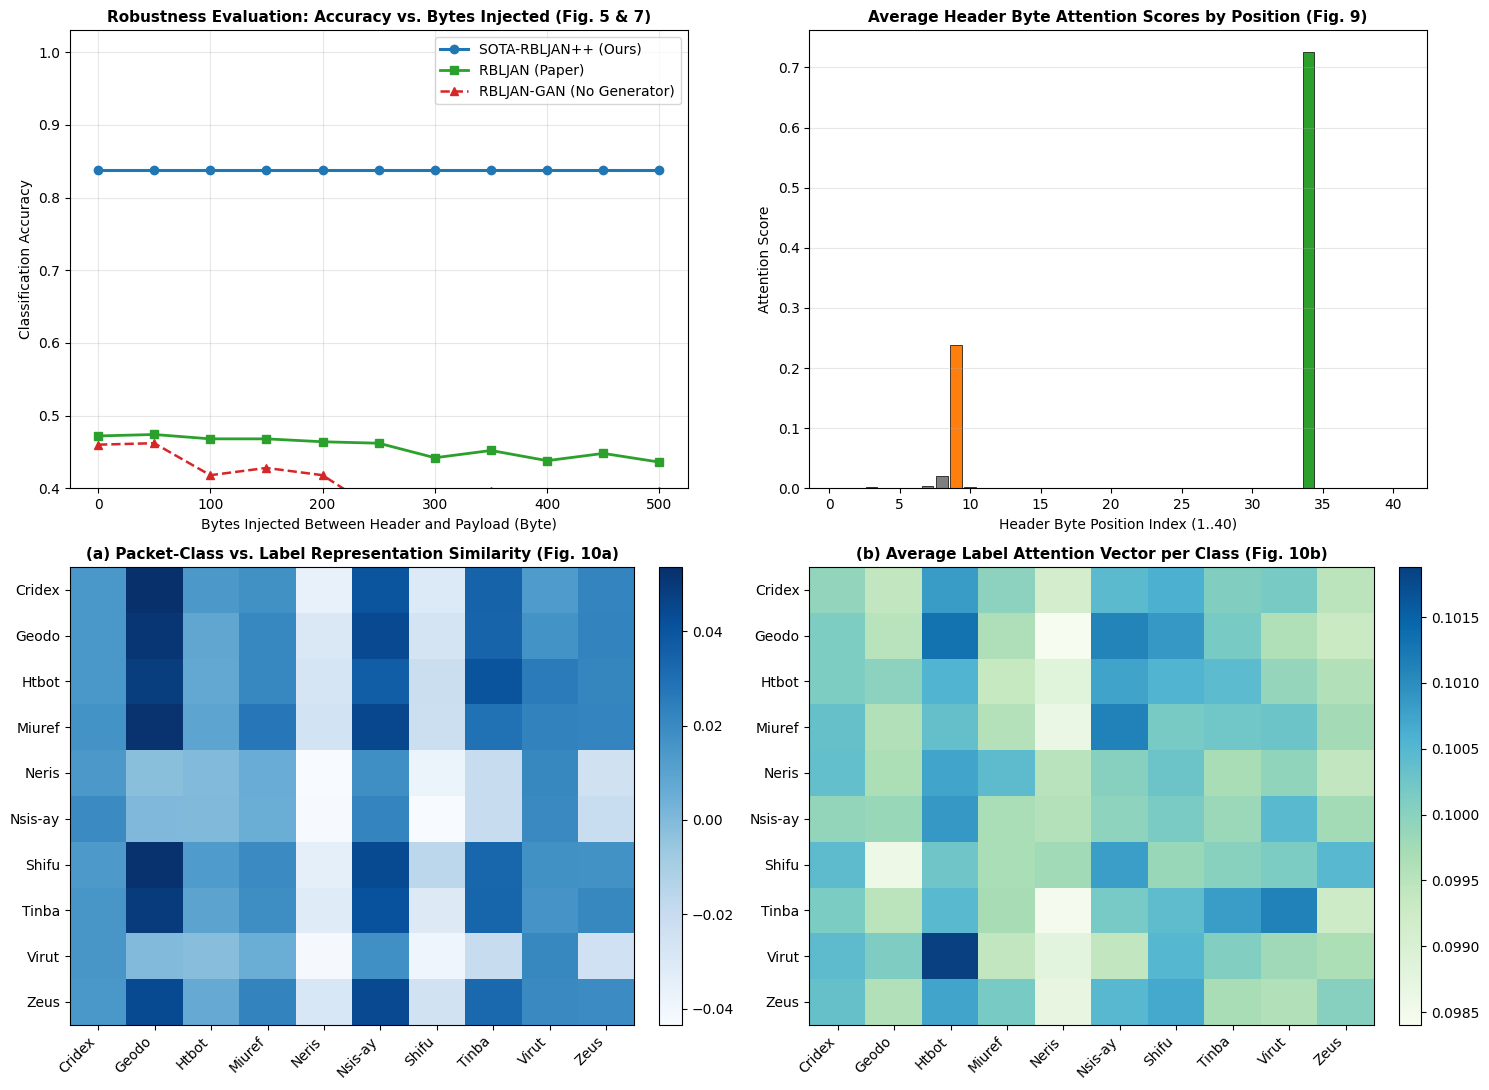

In [34]:
model_sota.eval()
all_h, all_alpha_h, all_beta, all_y = [], [], [], []

with torch.no_grad():
    for H, P, y in test_pkt_loader:
        H, P = H.to(DEVICE), P.to(DEVICE)
        _, _, details = model_sota(H, P, return_details=True)
        all_h.append(details["h"].cpu())
        all_alpha_h.append(details["alpha_h"].cpu())
        beta_avg = 0.5 * (details["beta_h"] + details["beta_p"])
        all_beta.append(beta_avg.cpu())
        all_y.append(y)
        L_hat_sota = details["L_hat"].cpu()

all_h = torch.cat(all_h, dim=0)
all_alpha_h = torch.cat(all_alpha_h, dim=0)
all_beta = torch.cat(all_beta, dim=0)
all_y = torch.cat(all_y, dim=0)

num_classes = 10
sim_matrix = np.zeros((num_classes, num_classes))
beta_matrix = np.zeros((num_classes, num_classes))
L_hat_norm = F.normalize(L_hat_sota, p=2, dim=-1)

for c in range(num_classes):
    mask = (all_y == c)
    if mask.sum() > 0:
        class_h_mean = all_h[mask].mean(dim=0, keepdim=True)
        class_h_norm = F.normalize(class_h_mean, p=2, dim=-1)
        sim_matrix[c] = torch.mm(class_h_norm, L_hat_norm.t()).squeeze(0).numpy()
        beta_matrix[c] = all_beta[mask].mean(dim=0).numpy()

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# Plot 1: Robustness Curve (Fig. 5 & Fig. 7)
ax = axes[0, 0]
ax.plot(injection_lengths, rob_sota, marker='o', linewidth=2.2, label='SOTA-RBLJAN++ (Ours)', color='#1f77b4')
ax.plot(injection_lengths, rob_base, marker='s', linewidth=2.0, label='RBLJAN (Paper)', color='#2ca02c')
ax.plot(injection_lengths, rob_nogan, marker='^', linestyle='--', linewidth=1.8, label='RBLJAN-GAN (No Generator)', color='#d62728')
ax.set_title("Robustness Evaluation: Accuracy vs. Bytes Injected (Fig. 5 & 7)", fontsize=11, fontweight='bold')
ax.set_xlabel("Bytes Injected Between Header and Payload (Byte)")
ax.set_ylabel("Classification Accuracy")
ax.set_ylim(0.4, 1.03)
ax.grid(True, alpha=0.3)
ax.legend()

# Plot 2: Header Byte Attention Scores (Fig. 9)
ax = axes[0, 1]
mean_header_attn = all_alpha_h.mean(dim=0).numpy()[:40]
bar_colors = ['#7f7f7f'] * 40
for idx in [0, 2, 3]: bar_colors[idx] = '#1f77b4'        # IP Header Len & Total Length
for idx in [8, 9]: bar_colors[idx] = '#ff7f0e'           # TTL & Protocol
for idx in range(20, 24): bar_colors[idx] = '#aec7e8'    # Well-Known Ports
for idx in [32, 33]: bar_colors[idx] = '#2ca02c'         # TCP Header Len & Flags
for idx in [34, 35]: bar_colors[idx] = '#9467bd'         # Window Size
ax.bar(np.arange(1, 41), mean_header_attn, color=bar_colors, edgecolor='black', linewidth=0.5)
ax.set_title("Average Header Byte Attention Scores by Position (Fig. 9)", fontsize=11, fontweight='bold')
ax.set_xlabel("Header Byte Position Index (1..40)")
ax.set_ylabel("Attention Score")
ax.grid(axis='y', alpha=0.3)

# Plot 3: Packet-Label Representation Cosine Similarity Matrix (Fig. 10a)
ax = axes[1, 0]
im1 = ax.imshow(sim_matrix, cmap="Blues", aspect="auto")
ax.set_title("(a) Packet-Class vs. Label Representation Similarity (Fig. 10a)", fontsize=11, fontweight='bold')
ax.set_xticks(range(num_classes))
ax.set_yticks(range(num_classes))
ax.set_xticklabels(USTC_TFC_CLASSES, rotation=45, ha="right")
ax.set_yticklabels(USTC_TFC_CLASSES)
plt.colorbar(im1, ax=ax, fraction=0.046, pad=0.04)

# Plot 4: Average Label Attention Matrix (Fig. 10b)
ax = axes[1, 1]
im2 = ax.imshow(beta_matrix, cmap="GnBu", aspect="auto")
ax.set_title("(b) Average Label Attention Vector per Class (Fig. 10b)", fontsize=11, fontweight='bold')
ax.set_xticks(range(num_classes))
ax.set_yticks(range(num_classes))
ax.set_xticklabels(USTC_TFC_CLASSES, rotation=45, ha="right")
ax.set_yticklabels(USTC_TFC_CLASSES)
plt.colorbar(im2, ax=ax, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()


### PyTorch Model Skeleton: RBLJAN Architecture

In [35]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class SinusoidalPositionalEncodingSkeleton(nn.Module):
    """Generates static sinusoidal positional encodings added to the byte embeddings."""
    def __init__(self, max_len: int, d_model: int):
        super().__init__()
        # Initialize static positional encoding matrix here
        pass

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x: [Batch, Sequence_Len, d_model]
        return x

class ByteAttentionEncoderSkeleton(nn.Module):
    """
    Applies 1D Convolution over the Similarity matrix G, performs BatchNorm,
    ReLU, Max-Pooling, and Softmax to obtain attention weights (alpha) over the grouped byte units.
    """
    def __init__(self, n_window: int, num_classes: int, K_kernels: int = 8):
        super().__init__()
        self.conv = nn.Conv1d(in_channels=num_classes, out_channels=K_kernels, kernel_size=n_window)
        self.bn = nn.BatchNorm1d(K_kernels)
        self.avg_pool = nn.AvgPool1d(kernel_size=n_window, stride=1)

    def forward(self, B_emb: torch.Tensor, G: torch.Tensor) -> torch.Tensor:
        # G: [Batch, Seq_Len, Num_Classes] -> Similarity Matrix
        # B_emb: [Batch, Seq_Len, E] -> Embedded byte sequences
        return torch.randn(B_emb.size(0), B_emb.size(-1), device=B_emb.device) # Returns representation vector h_b

class LabelAttentionEncoderSkeleton(nn.Module):
    """
    Groups the similarity scores along the sequence dimension into segments
    and feeds them through a two-stage FC network to produce label weights (beta).
    """
    def __init__(self, S_len: int, s_groups: int = 10):
        super().__init__()
        self.fc1 = nn.Linear(S_len // s_groups, 1)
        self.fc2 = nn.Linear(s_groups, 1)

    def forward(self, L_emb: torch.Tensor, G: torch.Tensor) -> torch.Tensor:
        # L_emb: [Num_Classes, E]
        # G: [Batch, Seq_Len, Num_Classes]
        return torch.randn(G.size(0), L_emb.size(-1), device=G.device) # Returns representation vector h_l

class RBLJANSkeleton(nn.Module):
    """
    Complete RBLJAN Network Classifier implementing the robust dual-channel strategy.
    """
    def __init__(self, num_classes: int = 10, M: int = 50, P_len: int = 1450, E: int = 256):
        super().__init__()
        # 1. Byte and Label Embeddings for separate Header and Payload processing
        self.header_byte_emb = nn.Embedding(257, E, padding_idx=256)
        self.payload_byte_emb = nn.Embedding(257, E, padding_idx=256)
        self.header_pos_enc = SinusoidalPositionalEncodingSkeleton(M, E)
        self.payload_pos_enc = SinusoidalPositionalEncodingSkeleton(P_len, E)

        self.header_label_emb = nn.Embedding(num_classes, E)
        self.payload_label_emb = nn.Embedding(num_classes, E)

        # 2. Attention Encoders
        self.header_byte_ae = ByteAttentionEncoderSkeleton(n_window=17, num_classes=num_classes)
        self.payload_byte_ae = ByteAttentionEncoderSkeleton(n_window=65, num_classes=num_classes)

        self.header_label_ae = LabelAttentionEncoderSkeleton(S_len=M, s_groups=5)
        self.payload_label_ae = LabelAttentionEncoderSkeleton(S_len=P_len, s_groups=10)

        # 3. Final Multi-layer/Linear Classifier on concatenated representation
        self.classifier = nn.Linear(4 * E, num_classes)

    def compute_cosine_similarity(self, B_emb: torch.Tensor, L_emb: torch.Tensor) -> torch.Tensor:
        # G(i, j) = Cosine_Similarity(B_i, L_j)
        B_norm = F.normalize(B_emb, p=2, dim=-1)
        L_norm = F.normalize(L_emb, p=2, dim=-1)
        return torch.matmul(B_norm, L_norm.t())

    def forward(self, H: torch.Tensor, P: torch.Tensor):
        label_ids = torch.arange(self.classifier.out_features, device=H.device)

        # Map input tokens to representations
        H_emb = self.header_pos_enc(self.header_byte_emb(H))
        P_emb = self.payload_pos_enc(self.payload_byte_emb(P))
        L_h = self.header_label_emb(label_ids)
        L_p = self.payload_label_emb(label_ids)

        # Construct Joint Attention Grids
        G_h = self.compute_cosine_similarity(H_emb, L_h)
        G_p = self.compute_cosine_similarity(P_emb, L_p)

        # Extract representations
        h_b_h = self.header_byte_ae(H_emb, G_h)
        h_b_p = self.payload_byte_ae(P_emb, G_p)
        h_l_h = self.header_label_ae(L_h, G_h)
        h_l_p = self.payload_label_ae(L_p, G_p)

        # Concatenate dual channels & fully connect
        h = torch.cat([h_b_h, h_b_p, h_l_h, h_l_p], dim=-1)
        logits = self.classifier(h)

        # Label Regularization Projection
        L_hat = torch.cat([L_h, L_p, L_h, L_p], dim=-1)
        reg_logits = self.classifier(L_hat)

        return logits, reg_logits

### 12. Gumbel-Softmax Generator for STE-AdvGAN
Here we implement a standalone, testable class for `DifferentiableSTEAdvGenerator` showcasing how Gumbel-Softmax relaxation allows discrete token selection while passing straight-through gradients during backward propagation.

In [36]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class StandaloneSTEAdvGenerator(nn.Module):
    """
    Differentiable Adversarial Generator using Gumbel-Softmax straight-through estimation (STE).
    Maps continuous latent variables & packet structures to discrete-like byte-level embeddings.
    """
    def __init__(self, pkt_len: int = 1500, rand_dim: int = 64, max_adv_len: int = 96):
        super().__init__()
        self.pkt_len = pkt_len
        self.rand_dim = rand_dim
        self.max_adv_len = max_adv_len

        # MLP to generate probability logits over 256 vocabulary classes
        self.network = nn.Sequential(
            nn.Linear(pkt_len + rand_dim, 256),
            nn.BatchNorm1d(256),
            nn.GELU(),
            nn.Linear(256, max_adv_len * 256)
        )

    def forward(
        self,
        H: torch.Tensor,
        P: torch.Tensor,
        payload_emb_layer: nn.Embedding,
        tau: float = 1.0,
        hard: bool = True
    ):
        B, P_len = P.shape
        device = H.device

        # Normalize packet representation to assist MLPs
        raw_pkt = torch.cat([H, P], dim=1).float() / 256.0
        z = torch.randn(B, self.rand_dim, device=device)

        # Generate token logits [Batch, max_adv_len, 256]
        logits = self.network(torch.cat([raw_pkt, z], dim=1)).view(B, self.max_adv_len, 256)

        # Gumbel-Softmax Relaxation (Straight-Through if hard=True)
        y_soft = F.gumbel_softmax(logits, tau=tau, hard=hard, dim=-1)
        adv_byte_ids = torch.argmax(y_soft, dim=-1)

        # Map one-hot representations directly to embedding weights
        vocab_weights = payload_emb_layer.weight[:256, :]  # shape: [256, E]
        adv_soft_emb = torch.matmul(y_soft, vocab_weights)  # shape: [Batch, max_adv_len, E]

        # Slice a random perturbation length for payload injection
        s_tilde = torch.randint(16, self.max_adv_len + 1, (1,)).item()

        ins_ids = adv_byte_ids[:, :s_tilde]
        ins_emb = adv_soft_emb[:, :s_tilde, :]

        # Reconstruct perturbed payload
        orig_P_emb = payload_emb_layer(P)
        P_adv_ids = torch.cat([ins_ids, P], dim=1)[:, :P_len]
        P_adv_soft_emb = torch.cat([ins_emb, orig_P_emb], dim=1)[:, :P_len, :]

        return P_adv_ids, P_adv_soft_emb

# Quick validation run
if __name__ == "__main__":
    emb = nn.Embedding(257, 256, padding_idx=256)
    generator = StandaloneSTEAdvGenerator(pkt_len=1500, rand_dim=64, max_adv_len=96)

    dummy_H = torch.randint(0, 256, (4, 50))
    dummy_P = torch.randint(0, 256, (4, 1450))

    ids, soft_emb = generator(dummy_H, dummy_P, emb, tau=1.0)
    print("Generated Adversarial Payload ID Shape:", ids.shape)
    print("Generated Soft Embedding Shape:", soft_emb.shape)
    print("Differentiable gradient path active:", soft_emb.requires_grad)

Generated Adversarial Payload ID Shape: torch.Size([4, 1450])
Generated Soft Embedding Shape: torch.Size([4, 1450, 256])
Differentiable gradient path active: True
